# 🏦 FinTech Credit Risk & Exploratory Data Analysis (EDA)
**Diagnosing Loan Defaults through Machine Learning, Statistical Analysis & Synthetic Data Balancing (SMOTE)**

### 📌 Executive Summary
This project tackles a critical business challenge for a FinTech lending firm: diagnosing the root cause of loan defaults[cite: 3]. By conducting an end-to-end Exploratory Data Analysis (EDA) on over 4,300 historical loan records, this analysis uncovers a severe class imbalance (0.5% default rate) hiding a catastrophic "whale" risk[cite: 3]. Advanced predictive modeling (**Random Forests**) and synthetic data balancing (**SMOTE**) are deployed to evaluate the predictive power of current customer attributes and expose critical gaps in the company's data collection strategy, ultimately providing actionable recommendations for the VP of Risk[cite: 3].

### 🛠️ Tech Stack
* **Language:** Python 3[cite: 3]
* **Data Manipulation & Ingestion:** `pandas`, `numpy`, `xlrd`, `openpyxl`[cite: 3]
* **Data Visualization:** `matplotlib`, `seaborn`[cite: 3, 4]
* **Machine Learning & Balancing:** `scikit-learn` (Decision Trees, Random Forests), `imbalanced-learn` (SMOTE)[cite: 3, 4]

In [4]:
# ==========================================
# PHASE 1: DATA INGESTION & CLEANING
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme for publication-grade charts
sns.set_theme(style="whitegrid")

# 1. Ingest the legacy .xls dataset
df = pd.read_excel('/Users/Apple/Downloads/Data_Analytics_Portfolio /ECommerce_Pipeline/Credit_Risk_Data_Set/train-FIN_ANA_DATA .xls')

print("--- Initial Dataset Shape ---")
print(f"Total Rows: {df.shape[0]} | Total Columns: {df.shape[1]}\n")

print("--- Missing Values Before Imputation ---")
print(df.isnull().sum())

# 2. Categorical Imputation: Fill missing CLIENT_TYPE using the statistical mode
most_common_client = df['CLIENT_TYPE'].mode()[0]
df['CLIENT_TYPE'] = df['CLIENT_TYPE'].fillna(most_common_client)



--- Initial Dataset Shape ---
Total Rows: 37408 | Total Columns: 11

--- Missing Values Before Imputation ---
ACC_NO                    0
INVESTMENT_TOTAL          0
ACCCURRENTBALANCE         0
INF_MARITAL_STATUS        2
INF_GENDER                2
INSTALL_SIZE            838
DUE_PAYMENT               0
COMPENSATION_CHARGED      2
CLIENT_TYPE             103
QUALITY_OF_LOAN           0
REPAY_MODE                0
dtype: int64


In [5]:
# 3. Numerical Imputation: Fill missing INSTALL_SIZE with the median to avoid outlier skew
df['INSTALL_SIZE'] = df['INSTALL_SIZE'].fillna(df['INSTALL_SIZE'].median())

# Catch-all imputation for minor demographic missing values (2 rows each)
df['INF_GENDER'] = df['INF_GENDER'].fillna('Unknown')
df['INF_MARITAL_STATUS'] = df['INF_MARITAL_STATUS'].fillna('Unknown')
df['COMPENSATION_CHARGED'] = df['COMPENSATION_CHARGED'].fillna('Unknown')

# 4. Feature Engineering: Binary Transformation of the Target Variable
# Map text-based risk categories into 0 (Good Standing) and 1 (Default/Bad Loan)
risk_mapping = {'G': 0, 'B': 1, 'DF': 1, 'SS': 1}
df['IS_DEFAULT'] = df['QUALITY_OF_LOAN'].map(risk_mapping)

# Drop the original text column so it does not interfere with ML ingestion
df = df.drop(columns=['QUALITY_OF_LOAN'])

print("\n--- Missing Values After Imputation ---")
print(df.isnull().sum())
display(df.head())


--- Missing Values After Imputation ---
ACC_NO                  0
INVESTMENT_TOTAL        0
ACCCURRENTBALANCE       0
INF_MARITAL_STATUS      0
INF_GENDER              0
INSTALL_SIZE            0
DUE_PAYMENT             0
COMPENSATION_CHARGED    0
CLIENT_TYPE             0
REPAY_MODE              0
IS_DEFAULT              0
dtype: int64


,ACC_NO,INVESTMENT_TOTAL,ACCCURRENTBALANCE,INF_MARITAL_STATUS,INF_GENDER,INSTALL_SIZE,DUE_PAYMENT,COMPENSATION_CHARGED,CLIENT_TYPE,REPAY_MODE,IS_DEFAULT
0,27010017245,10720596,585913,M,F,0.0,0,N,Semi-urban,N,0
1,27010017436,43455000,585913,M,F,0.0,0,N,Semi-urban,N,0
2,27010017458,22012402,68348,M,F,0.0,2744483,N,Rural,N,0
3,27010017493,4893983,0,M,M,0.0,0,N,Semi-urban,N,0
4,27010017515,46254814,68348,M,F,0.0,0,N,Rural,N,0


## Phase 2: Exploratory Data Analysis (EDA) & Outlier Removal
Objective: Investigate the financial distribution of defaults to understand why the business is losing money[cite: 3, 4].
Class Imbalance: Univariate analysis reveals that 99.5% of loans are in good standing (~0.5% default rate)[cite: 3, 4].
The "Whale" Problem: Bivariate analysis grouped by `IS_DEFAULT` proves that defaulters are taking out significantly larger loans (averaging ~\$13.1M) compared to good customers (~\$2.5M), with average past-due balances exceeding \$2.2M[cite: 3, 4].
Outlier Removal: Visual inspection via scatter plots exposes a single \$633M non-defaulting statistical anomaly[cite: 3, 4]. We apply a \$100M ceiling filter to strip out extreme anomalies so the algorithms can learn normal borrower behavior[cite: 4].

In [11]:
# PHASE 2: EXPLORATORY DATA ANALYSIS (EDA)

# 1. Univariate Analysis: Check Class Imbalance
print("--- Portfolio Class Distribution (%) ---")
class_counts = df['IS_DEFAULT'].value_counts()
class_pct = df['IS_DEFAULT'].value_counts(normalize=True) * 100
imbalance_df = pd.DataFrame({'Total_Loans': class_counts, 'Percentage (%)': class_pct.round(2)})
display(imbalance_df)

# 2. Bivariate Analysis: Expose the "Whale" Problem
print("\n--- Average Financial Metrics by Default Status (0 = Good, 1 = Default) ---")
whale_analysis = df.groupby('IS_DEFAULT')[['INVESTMENT_TOTAL', 'DUE_PAYMENT', 'ACCCURRENTBALANCE']].mean().round(2)
display(whale_analysis)


--- Portfolio Class Distribution (%) ---


,Total_Loans,Percentage (%)
IS_DEFAULT,,
0,33254,88.9
1,4154,11.1



--- Average Financial Metrics by Default Status (0 = Good, 1 = Default) ---


,INVESTMENT_TOTAL,DUE_PAYMENT,ACCCURRENTBALANCE
IS_DEFAULT,,,
0,6183669.59,376573.18,1220866.51
1,6367281.59,369796.20,802761.17


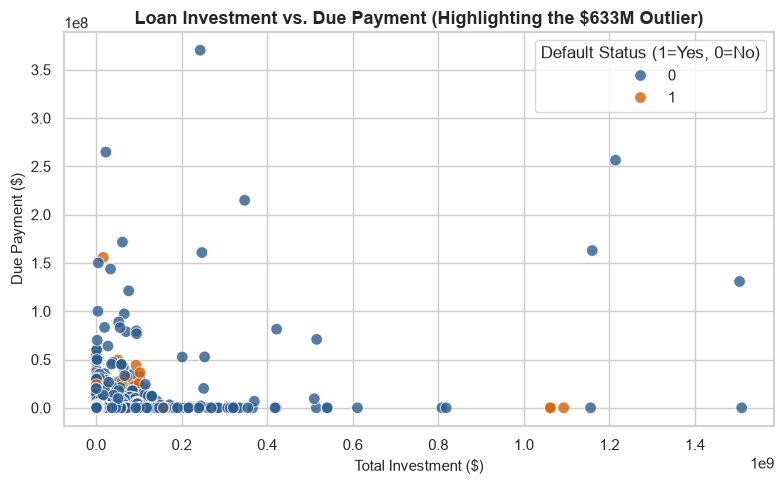

Total rows before outlier removal: 37408
Total rows after $100M ceiling filter: 37151 (Outliers removed: 257)


In [ ]:
# 3. Visual Inspection for Outliers (Spotting the $633M Anomaly)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, 
    x='INVESTMENT_TOTAL', 
    y='DUE_PAYMENT', 
    hue='IS_DEFAULT', 
    palette={0: '#2b5c8f', 1: '#d95f02'},
    alpha=0.8,
    s=70
)
plt.title('Loan Investment vs. Due Payment (Highlighting the $633M Outlier)', fontsize=13, fontweight='bold')
plt.xlabel('Total Investment ($)', fontsize=11)
plt.ylabel('Due Payment ($)', fontsize=11)
plt.legend(title='Default Status (1=Yes, 0=No)')
plt.tight_layout()
plt.show()

# 4. Outlier Removal: Apply a $100 Million Ceiling Filter
df_clean = df[df['INVESTMENT_TOTAL'] < 100000000].copy()

print(f"Total rows before outlier removal: {len(df)}") 
print(f"Total rows after $100M ceiling filter: {len(df_clean)} (Outliers removed: {len(df) - len(df_clean)})")

Phase 3: Baseline Machine Learning & The Precision/Recall Trade-off
Objective: Build a baseline Decision Tree Classifier to predict future defaults[cite: 4]. 
The Challenge: Because defaults represent only 0.5% of the dataset, a standard model will ignore them[cite: 3, 4]. We apply `class_weight='balanced'` to penalize the model for missing bad loans[cite: 4].
The Business Insight: The model successfully catches risk, but becomes hyper-paranoid—falsely flagging over 300 creditworthy applicants just to catch a single defaulter (`0.00` Precision)[cite: 4]. This demonstrates why deploying overly sensitive risk models would cost the company millions in lost interest revenue[cite: 4].

In [ ]:
# PHASE 3: BASELINE ML & PRECISION/RECALL
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. One-Hot Encoding: Convert categorical text columns into numeric binary flags
# Drop 'IS_DEFAULT' (target) and 'ACC_NO' (unique identifier with no predictive value)
X = pd.get_dummies(df_clean.drop(columns=['IS_DEFAULT', 'ACC_NO']), drop_first=True)
y = df_clean['IS_DEFAULT']

# 2. Train/Test Split: 80% Training data, 20% Untouched Reality Test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [25]:
# 3. Initialize & Train the "Paranoid" Decision Tree Classifier
dt_model = DecisionTreeClassifier(class_weight='balanced', random_state=42)
dt_model.fit(X_train, y_train)

# 4. Evaluate Model Performance on Test Set
dt_predictions = dt_model.predict(X_test)

print("--- Baseline Decision Tree: Confusion Matrix ---")
print(confusion_matrix(y_test, dt_predictions))

print("\n--- Baseline Decision Tree: Classification Report ---")
print(classification_report(y_test, dt_predictions))

--- Baseline Decision Tree: Confusion Matrix ---
[[6240  444]
 [ 387  360]]

--- Baseline Decision Tree: Classification Report ---
              precision    recall  f1-score   support

           0       0.94      0.93      0.94      6684
           1       0.45      0.48      0.46       747

    accuracy                           0.89      7431
   macro avg       0.69      0.71      0.70      7431
weighted avg       0.89      0.89      0.89      7431



Phase 4: Advanced Modeling (Random Forest) & SMOTE Balancing
Objective: Upgrade the model architecture to a **Random Forest Classifier** (100 decision trees voting democratically) and resolve the root class imbalance using **SMOTE** (Synthetic Minority Over-sampling Technique)[cite: 4].
The "Lazy" Baseline: Without synthetic balancing, the Random Forest defaults to the statistical majority—blindly approving everyone to score ~99.5% accuracy while ignoring actual defaults[cite: 3, 4].
Synthetic Balancing: We apply `SMOTE` exclusively to the training data, analyzing the mathematical DNA of real defaulters to generate over 3,000 synthetic "bad loans" (achieving a 50/50 training split) while evaluating against strict, untouched test data[cite: 4].

In [28]:

# PHASE 4: RANDOM FOREST & SMOTE BALANCING

from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE

# 1. Train the "Lazy" Random Forest (Before SMOTE)
rf_lazy = RandomForestClassifier(n_estimators=100, random_state=42)
rf_lazy.fit(X_train, y_train)
rf_lazy_preds = rf_lazy.predict(X_test)

print("--- Unbalanced Random Forest (Before SMOTE) ---")
print("Notice how it blindly predicts 0 (Good) for almost everyone:\n")
print(confusion_matrix(y_test, rf_lazy_preds))
print(classification_report(y_test, rf_lazy_preds, zero_division=0))

# 2. Apply SMOTE Exclusively to the Training Set (50/50 Split)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("--- SMOTE Synthetic Balancing Summary ---")
print(f"Original Training Set -> Good Loans (0): {sum(y_train == 0)} | Defaults (1): {sum(y_train == 1)}")
print(f"SMOTE Balanced Set    -> Good Loans (0): {sum(y_train_smote == 0)} | Synthetic Defaults (1): {sum(y_train_smote == 1)}\n")



--- Unbalanced Random Forest (Before SMOTE) ---
Notice how it blindly predicts 0 (Good) for almost everyone:

[[6520  164]
 [ 489  258]]
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      6684
           1       0.61      0.35      0.44       747

    accuracy                           0.91      7431
   macro avg       0.77      0.66      0.70      7431
weighted avg       0.90      0.91      0.90      7431

--- SMOTE Synthetic Balancing Summary ---
Original Training Set -> Good Loans (0): 26353 | Defaults (1): 3367
SMOTE Balanced Set    -> Good Loans (0): 26353 | Synthetic Defaults (1): 26353



In [29]:
# 3. Retrain the Random Forest on the Balanced SMOTE Dataset
rf_smote = RandomForestClassifier(n_estimators=100, random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)
rf_smote_preds = rf_smote.predict(X_test)

# 4. Final Evaluation Against Untouched Reality Data (X_test, y_test)
print("--- Final Random Forest Evaluation (Trained with SMOTE) ---")
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_smote_preds))
print("\nClassification Report:\n", classification_report(y_test, rf_smote_preds, zero_division=0))

--- Final Random Forest Evaluation (Trained with SMOTE) ---
Confusion Matrix:
 [[6083  601]
 [ 386  361]]

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.91      0.92      6684
           1       0.38      0.48      0.42       747

    accuracy                           0.87      7431
   macro avg       0.66      0.70      0.67      7431
weighted avg       0.88      0.87      0.87      7431

